## 1. Importación de Librerías y Configuración Inicial

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Carga y Exploración de Datos

In [14]:
# Ruta del archivo cargado
data_path = '/content/drive/MyDrive/Modelos/PrestamosDataset/loan_approval_dataset.csv'
df = pd.read_csv(data_path)


# Exploración inicial del dataset
df.head(10)
df.info()
print("Duplicated rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB
Duplicated rows

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 3. Análisis y Visualización de Datos

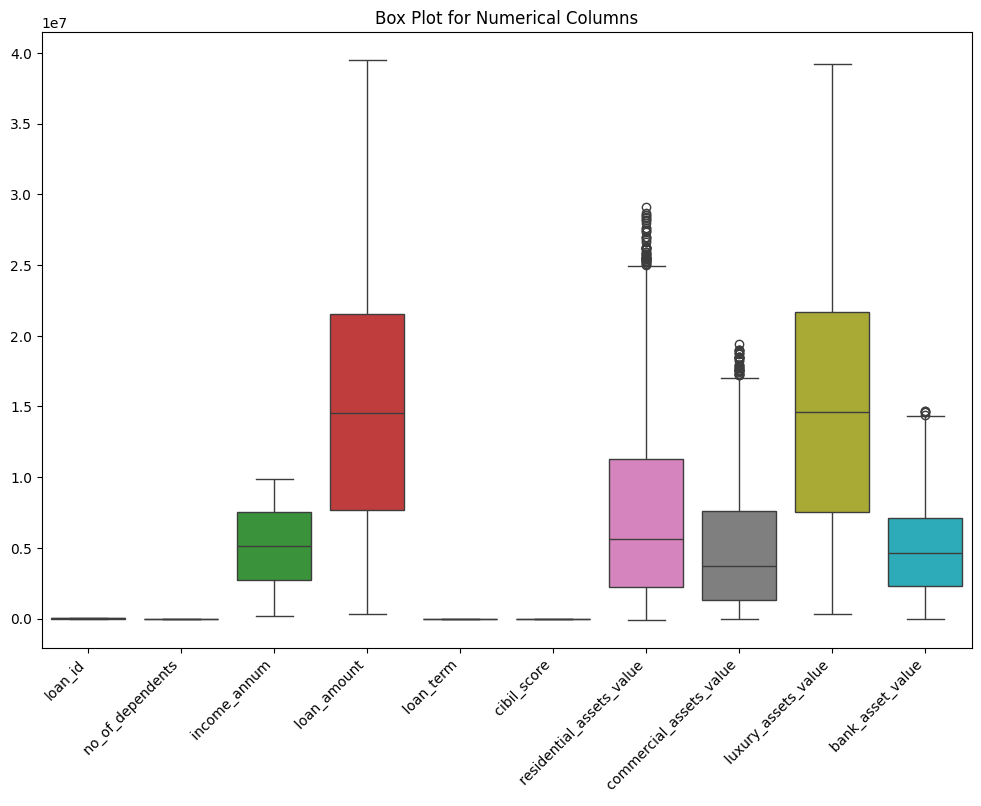

In [15]:
numerical_columns = df.select_dtypes(include=['number'])
plt.figure(figsize=(12, 8))
sns.boxplot(data=numerical_columns)
plt.title("Box Plot for Numerical Columns")
plt.xticks(rotation=45, ha="right")
plt.show()

## 4. Preprocesamiento de Datos

In [24]:
# Quitar espacios en blanco al inicio y al final de los nombres de las columnas
df.columns = df.columns.str.strip()

# Asegurarnos de que los valores en 'loan_status' no tengan espacios ni diferencias de mayúsculas/minúsculas
df['loan_status'] = df['loan_status'].str.strip().str.upper()

# Eliminar filas con valores nulos o vacíos en 'loan_status'
df = df.dropna(subset=['loan_status'])

# Definir las características y la variable objetivo
X = df.drop(columns=['loan_id', 'loan_status'])  # Eliminamos 'loan_id' y 'loan_status'
y = df['loan_status'].apply(lambda x: 1 if 'APPROVED' in x else 0)  # Convertimos 'loan_status' en binario

## 5. Codificación de Variables Categóricas

In [25]:
# Convertir variables categóricas en dummies
X = pd.get_dummies(X, columns=['education', 'self_employed'], drop_first=True)

## 6. División de los Datos en Conjuntos de Entrenamiento y Prueba

In [26]:
from sklearn.model_selection import train_test_split

# División estratificada de los datos para asegurar ambas clases en y_train
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Verificar la distribución de clases en y_train
print("Distribución de clases en y_train:")
print(y_train.value_counts())

Distribución de clases en y_train:
loan_status
1    2125
0    1290
Name: count, dtype: int64


## 7. Creación y Entrenamiento de los Modelos con Pipelines

In [27]:
# Pipelines de clasificación
pipeline_rf = Pipeline([('scaler', StandardScaler()), ('classifier', RandomForestClassifier())])
pipeline_svm = Pipeline([('scaler', StandardScaler()), ('classifier', SVC(probability=True))])
pipeline_lr = Pipeline([('scaler', StandardScaler()), ('classifier', LogisticRegression())])

# Entrenamiento
pipeline_rf.fit(X_train, y_train)
pipeline_svm.fit(X_train, y_train)
pipeline_lr.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegression())])

## 8. Evaluación del Modelo

Random Forest Accuracy: 0.9812646370023419
SVM Accuracy: 0.9449648711943794
Logistic Regression Accuracy: 0.9133489461358314


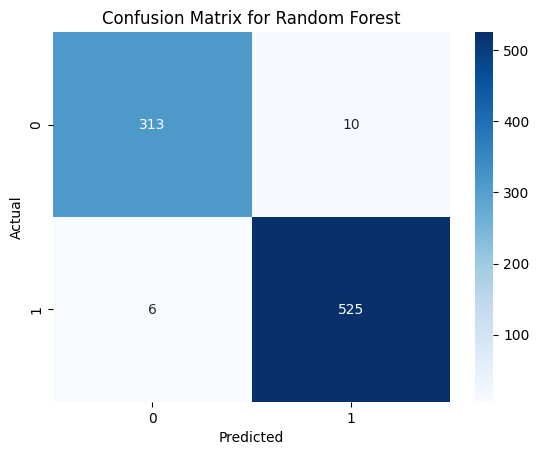

In [28]:
# Predicciones
y_pred_rf = pipeline_rf.predict(X_test)
y_pred_svm = pipeline_svm.predict(X_test)
y_pred_lr = pipeline_lr.predict(X_test)

# Exactitud de cada modelo
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))

# Matriz de Confusión para el modelo de Random Forest
conf_matrix = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix for Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 9. Búsqueda de Hiperparámetros con GridSearchCV

In [32]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

# Definir el pipeline
pipeline_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier())
])

# Hiperparámetros de RandomForestClassifier (sin 'classifier__')
param_grid_rf = {
    'classifier__n_estimators': [10, 50, 100],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5, 10],
}

# Aplicar GridSearchCV sobre el pipeline completo
grid_search_rf = GridSearchCV(pipeline_rf, param_grid_rf, cv=5)

# Ajuste del modelo y obtención de los mejores parámetros
grid_search_rf.fit(X_train, y_train)
best_params_rf = grid_search_rf.best_params_
print("Best Hyperparameters for RandomForestClassifier:", best_params_rf)


Best Hyperparameters for RandomForestClassifier: {'classifier__max_depth': 20, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 50}


## 10. Generación de las Métricas de Evaluación


Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.98      0.98       323
           1       0.98      0.99      0.99       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



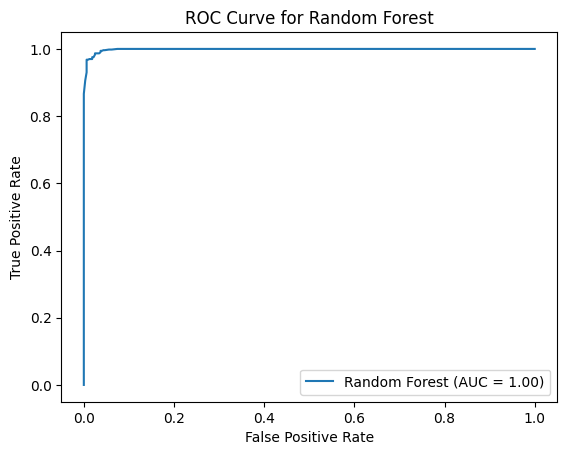

In [34]:
from sklearn.metrics import classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Generar predicciones con el mejor modelo encontrado por GridSearchCV
y_pred_rf_cv = grid_search_rf.predict(X_test)
print("Classification Report:\n", classification_report(y_test, y_pred_rf_cv))

# Curva ROC y AUC
y_proba_rf = grid_search_rf.predict_proba(X_test)[:, 1]  # Probabilidades para la clase positiva (1)
fpr, tpr, _ = roc_curve(y_test, y_proba_rf)
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_proba_rf):.2f})')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Random Forest")
plt.legend(loc="best")
plt.show()

## 11. Pruebas Manuales

In [47]:
import pandas as pd

# Definir input_data como un DataFrame con los mismos nombres de columna que X_train
input_data = pd.DataFrame([[2, 4100000, 29900000, 5, 400, 24000, 176000, 22700, 8000, 0, 0]],
                          columns=['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score',
                                   'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value',
                                   'bank_asset_value', 'education_ Not Graduate', 'self_employed_ Yes'])

# Realizar la predicción con el mejor modelo encontrado por GridSearchCV
prediction = grid_search_rf.predict(input_data)
print("EJEMPLO 1: Loan Approval Prediction:", "Approved" if prediction[0] == 1 else "Denied")

# Definir input_data con los valores del cliente que probablemente será denegado
input_data2 = pd.DataFrame([[3, 500000, 15000000, 20, 400, 500000, 0, 200000, 100000, 1, 0]],
                          columns=['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score',
                                   'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value',
                                   'bank_asset_value', 'education_ Not Graduate', 'self_employed_ Yes'])

# Realizar la predicción con el modelo
prediction = grid_search_rf.predict(input_data2)
print("EJEMPLO 2: Loan Approval Prediction:", "Approved" if prediction[0] == 1 else "Denied")

EJEMPLO 1: Loan Approval Prediction: Approved
EJEMPLO 2: Loan Approval Prediction: Denied
